In [1]:
# --- Install required libraries ---
!pip install torch torchvision matplotlib medmnist pytorch-fid --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.2/87.2 kB 2.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.7 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.6 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.2 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 31.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 13.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 2.0 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 83.0 MB/s eta 0:00:00:00:0100:01


In [2]:
# ---------------- Standard Libraries ----------------
import os
import math
import copy

# ---------------- Image and Plotting ----------------
import imageio
import numpy as np
import matplotlib.pyplot as plt

# ---------------- TQDM ----------------
from tqdm.notebook import trange, tqdm

# ---------------- PyTorch Core ----------------
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.utils.data as data
from torch.utils.data import Dataset, DataLoader, ConcatDataset

# ---------------- TorchVision ----------------
import torchvision
from torchvision import datasets, transforms
import torchvision.utils as vutils
from torchvision.utils import save_image, make_grid
import torchvision.transforms.functional as TF

# ---------------- External Libraries ----------------
from pytorch_fid.fid_score import calculate_fid_given_paths

# ---------------- MedMNIST ----------------
import medmnist
from medmnist import INFO, Evaluator

In [3]:
print(f"MedMNIST v{medmnist.__version__} @ {medmnist.HOMEPAGE}")

MedMNIST v3.0.2 @ https://github.com/MedMNIST/MedMNIST/


In [4]:
data_flag = 'bloodmnist'
download = True
BATCH_SIZE = 128

info = INFO[data_flag]
task = info['task']
n_channels = info['n_channels']
n_classes = len(info['label'])

DataClass = getattr(medmnist, info['python_class'])

In [5]:

# preprocessing
data_transform = transforms.Compose([
    transforms.Resize((32, 32)), 
    transforms.ToTensor(),       
])


# Load all splits
train = DataClass(split='train', transform=data_transform, download=True)
val = DataClass(split='val', transform=data_transform, download=True)
test = DataClass(split='test', transform=data_transform, download=True)

# Combine them into a single dataset
full_dataset = ConcatDataset([train, val, test])
dataloader = DataLoader(full_dataset, batch_size=128, shuffle=True)

100%|██████████| 35.5M/35.5M [01:16<00:00, 463kB/s]


In [6]:
class ConditionalNorm2d(nn.Module):
    def __init__(self, channels, num_features, norm_type="gn"):
        super(ConditionalNorm2d, self).__init__()
        self.channels = channels
        if norm_type == "bn":
            self.norm = nn.BatchNorm2d(channels, affine=False, eps=1e-4)
        elif norm_type == "gn":
            self.norm = nn.GroupNorm(8, channels, affine=False, eps=1e-4)
        else:
            raise ValueError("Normalisation type not recognised.")

        self.fcw = nn.Linear(num_features, channels)
        self.fcb = nn.Linear(num_features, channels)

    def forward(self, x, features):
        out = self.norm(x)
        w = self.fcw(features)
        b = self.fcb(features)

        out = w.view(-1, self.channels, 1, 1) * out + b.view(-1, self.channels, 1, 1)
        return out


class ResDown(nn.Module):
    """
    Residual down sampling block
    """

    def __init__(self, channel_in, channel_out, kernel_size=3, num_features=128):
        super(ResDown, self).__init__()
        self.norm1 = ConditionalNorm2d(channel_in, num_features=num_features)

        self.conv1 = nn.Conv2d(channel_in, channel_out, kernel_size, 2, kernel_size // 2)
        self.norm2 = ConditionalNorm2d(channel_out, num_features=num_features)

        self.conv2 = nn.Conv2d(channel_out, channel_out, kernel_size, 1, kernel_size // 2)

        self.conv3 = nn.Conv2d(channel_in, channel_out, kernel_size, 2, kernel_size // 2)

        self.act_fnc = nn.ELU()

    def forward(self, x, features):
        x = self.act_fnc(self.norm1(x, features))

        skip = self.conv3(x)

        x = self.act_fnc(self.norm2(self.conv1(x), features))
        x = self.conv2(x)

        return x + skip


class ResUp(nn.Module):
    """
    Residual up sampling block
    """

    def __init__(self, channel_in, channel_out, kernel_size=3, scale_factor=2, num_features=128):
        super(ResUp, self).__init__()
        self.norm1 = ConditionalNorm2d(channel_in, num_features=num_features)

        self.conv1 = nn.Conv2d(channel_in, channel_in, kernel_size, 1, kernel_size // 2)
        self.norm2 = ConditionalNorm2d(channel_in, num_features=num_features)

        self.conv2 = nn.Conv2d(channel_in, channel_out, kernel_size, 1, kernel_size // 2)

        self.conv3 = nn.Conv2d(channel_in, channel_out, kernel_size, 1, kernel_size // 2)

        self.up_nn = nn.Upsample(scale_factor=scale_factor, mode="nearest")

        self.act_fnc = nn.ELU()

    def forward(self, x, features):
        x = self.up_nn(self.act_fnc(self.norm1(x, features)))

        skip = self.conv3(x)

        x = self.act_fnc(self.norm2(self.conv1(x), features))
        x = self.conv2(x)

        return x + skip


class ResBlock(nn.Module):
    """
    Residual block
    """

    def __init__(self, channel_in, channel_out, kernel_size=3, num_features=128):
        super(ResBlock, self).__init__()
        self.norm1 = ConditionalNorm2d(channel_in, num_features=num_features)

        self.conv1 = nn.Conv2d(channel_in, channel_in, kernel_size, 1, kernel_size // 2)
        self.norm2 = ConditionalNorm2d(channel_in, num_features=num_features)

        self.conv2 = nn.Conv2d(channel_in, channel_out, kernel_size, 1, kernel_size // 2)

        if not channel_in == channel_out:
            self.conv3 = nn.Conv2d(channel_in, channel_out, kernel_size, 1, kernel_size // 2)
        else:
            self.conv3 = None

        self.act_fnc = nn.ELU()

    def forward(self, x_in, features):
        x = self.act_fnc(self.norm1(x_in, features))

        if self.conv3 is not None:
            skip = self.conv3(x)
        else:
            skip = x_in

        x = self.act_fnc(self.norm2(self.conv1(x), features))
        x = self.conv2(x)

        return x + skip


class Encoder(nn.Module):
    """
    Encoder block
    """

    def __init__(self, channels, ch=64, blocks=(1, 2, 4), num_features=128):
        super(Encoder, self).__init__()
        self.conv_in = nn.Conv2d(channels, blocks[0] * ch, 3, 1, 1)

        widths_in = list(blocks)
        widths_out = list(blocks[1:]) + [blocks[-1]]

        self.layer_blocks = nn.ModuleList([])

        for w_in, w_out in zip(widths_in, widths_out):
            self.layer_blocks.append(ResDown(w_in * ch, w_out * ch, num_features=num_features))

        self.block_out = ResBlock(w_out * ch, w_out * ch, num_features=num_features)

        self.act_fnc = nn.ELU()

    def forward(self, x, index_features):
        x = self.conv_in(x)
        skip_list = [x]

        for block in self.layer_blocks:
            x = block(x, index_features)
            skip_list.append(x)
        
        x = self.block_out(x, index_features)
        return x, skip_list


class Decoder(nn.Module):
    """
    Decoder block
    Built to be a mirror of the encoder block
    """

    def __init__(self, channels, ch=64, blocks=(1, 2, 4), num_features=128):
        super(Decoder, self).__init__()
        
        widths_out = list(blocks)[::-1]
        widths_in = (list(blocks[1:]) + [blocks[-1]])[::-1]

        self.block_in = ResBlock(blocks[-1] * ch, blocks[-1] * ch, num_features=num_features)
        
        self.layer_blocks = nn.ModuleList([])

        for w_in, w_out in zip(widths_in, widths_out):
            self.layer_blocks.append(ResUp(w_in * ch * 2, w_out * ch, num_features=num_features))

        self.conv_out = nn.Conv2d(blocks[0] * ch * 2, channels, 3, 1, 1)
        self.act_fnc = nn.ELU()

    def forward(self, x_in, skip_list, index_features):
        x = self.block_in(x_in, index_features)
        
        for block in self.layer_blocks:
            skip = skip_list.pop()
            x = torch.cat((x, skip), 1)
            x = block(x, index_features)
            
        skip = skip_list.pop()
        x = torch.cat((x, skip), 1)
        return self.conv_out(x)

    
class SinusoidalPosEmb(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, x):
        device = x.device
        half_dim = self.dim // 2
        emb = math.log(10000) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=device) * -emb)
        emb = x[:, None] * emb[None, :]
        emb = torch.cat((emb.sin(), emb.cos()), dim=-1)
        return emb


class Unet(nn.Module):
    """
    Unet network, uses the above encoder and decoder blocks
    """
    def __init__(self, channel_in=3, ch=32, blocks=(1, 2, 4), timesteps=20, num_features=128):
        super(Unet, self).__init__()        
        self.time_mlp = nn.Sequential(
            SinusoidalPosEmb(num_features),
            nn.Linear(num_features, 2 * num_features),
            nn.GELU(),
            nn.Linear(2 * num_features, num_features),
            nn.GELU()
        )
        
        self.encoder = Encoder(channel_in, ch=ch, blocks=blocks, num_features=num_features)
        self.decoder = Decoder(channel_in, ch=ch, blocks=blocks, num_features=num_features)

    def forward(self, x, index):
        index_features = self.time_mlp(index)
        
        bottleneck, skip_list = self.encoder(x, index_features)
        recon_img = self.decoder(bottleneck, skip_list, index_features)
        return recon_img

In [7]:
def cosine_alphas_bar(timesteps, s=0.008):
    steps = timesteps + 1
    x = torch.linspace(0, steps, steps)
    alphas_bar = torch.cos(((x / steps) + s) / (1 + s) * torch.pi * 0.5) ** 2
    alphas_bar = alphas_bar / alphas_bar[0]
    return alphas_bar[:timesteps]

In [8]:
def noise_from_x0(curr_img, img_pred, alpha):
    return (curr_img - alpha.sqrt() * img_pred)/((1 - alpha).sqrt() + 1e-4)

In [9]:
def cold_diffuse(diffusion_model, sample_in, total_steps):
    diffusion_model.eval()
    bs = sample_in.shape[0]
    alphas = torch.flip(cosine_alphas_bar(total_steps), (0,)).to(device)
    random_sample = copy.deepcopy(sample_in)
    with torch.no_grad():
        for i in trange(total_steps - 1):
            index = (i * torch.ones(bs, device=sample_in.device)).long()

            img_output = diffusion_model(random_sample, index)

            noise = noise_from_x0(random_sample, img_output, alphas[i])
            x0 = img_output

            rep1 = alphas[i].sqrt() * x0 + (1 - alphas[i]).sqrt() * noise
            rep2 = alphas[i + 1].sqrt() * x0 + (1 - alphas[i + 1]).sqrt() * noise

            random_sample += rep2 - rep1

        index = ((total_steps - 1) * torch.ones(bs, device=sample_in.device)).long()
        img_output = diffusion_model(random_sample, index)

    return img_output

In [10]:
# Create a dataloader itterable object
dataiter = iter(dataloader)
# Sample from the itterable object
images, labels = next(dataiter)

In [11]:
timesteps = 50
use_cuda = torch.cuda.is_available()
gpu_indx  = 0
device = torch.device(gpu_indx if use_cuda else "cpu")
img_size = 32
lr = 1e-4
train_epoch = 100
batch_size = 128

# network
u_net = Unet(channel_in=images.shape[1], ch=32, blocks=(1, 2, 4), timesteps=timesteps).to(device)

#A fixed latent noise vector so we can see the improvement over the epochs
fixed_latent_noise = torch.randn(images.shape[0], images.shape[1], img_size, img_size).to(device)

# Adam optimizer
optimizer = optim.Adam(u_net.parameters(), lr=lr)
lr_schedule = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=train_epoch, eta_min=0)

In [12]:
loss_log = []
mean_loss = 0

alphas = torch.flip(cosine_alphas_bar(timesteps), (0,)).to(device)

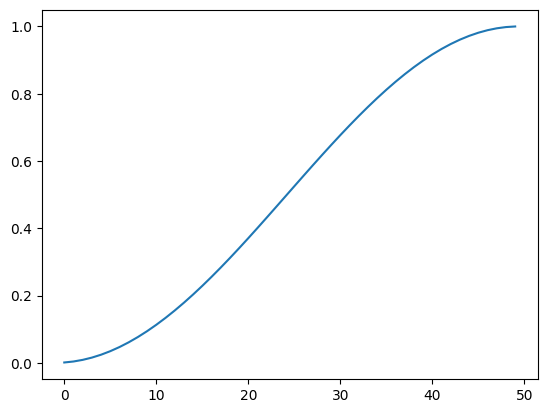

In [13]:
_ = plt.plot(alphas.cpu())

## **Training**

In [14]:
pbar = trange(train_epoch, leave=False, desc="Epoch")    
u_net.train()
for epoch in pbar:
    pbar.set_postfix_str('Loss: %.4f' % (mean_loss/len(dataloader)))
    mean_loss = 0

    for num_iter, (images, labels) in enumerate(tqdm(dataloader, leave=False)):

        images = images.to(device)
        
        #the size of the current minibatch
        bs = images.shape[0]

        rand_index = torch.randint(timesteps, (bs, ), device=device)
        random_sample = torch.randn_like(images)
        alpha_batch = alphas[rand_index].reshape(bs, 1, 1, 1)
        
        noise_input = alpha_batch.sqrt() * images + (1 - alpha_batch).sqrt() * random_sample

        img_pred = u_net(noise_input, rand_index)
        
        loss = F.l1_loss(img_pred, images)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        #log the generator training loss
        loss_log.append(loss.item())
        mean_loss += loss.item()
        
    lr_schedule.step()

Epoch:   0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/134 [00:00<?, ?it/s]

  0%|          | 0/134 [00:00<?, ?it/s]

  0%|          | 0/134 [00:00<?, ?it/s]

  0%|          | 0/134 [00:00<?, ?it/s]

...

  0%|          | 0/134 [00:00<?, ?it/s]

  0%|          | 0/134 [00:00<?, ?it/s]

  0%|          | 0/134 [00:00<?, ?it/s]

  0%|          | 0/134 [00:00<?, ?it/s]

  0%|          | 0/134 [00:00<?, ?it/s]

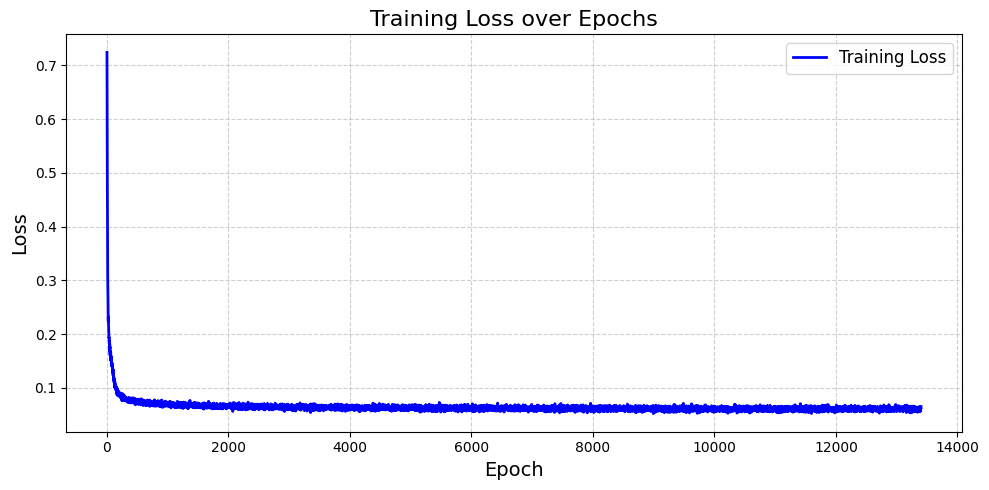

In [15]:
#------------- Loss Plot -------------#
plt.figure(figsize=(10, 5))
plt.plot(loss_log, color='blue', linewidth=2, label='Training Loss')
plt.title('Training Loss over Epochs', fontsize=16)
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

  0%|          | 0/49 [00:00<?, ?it/s]

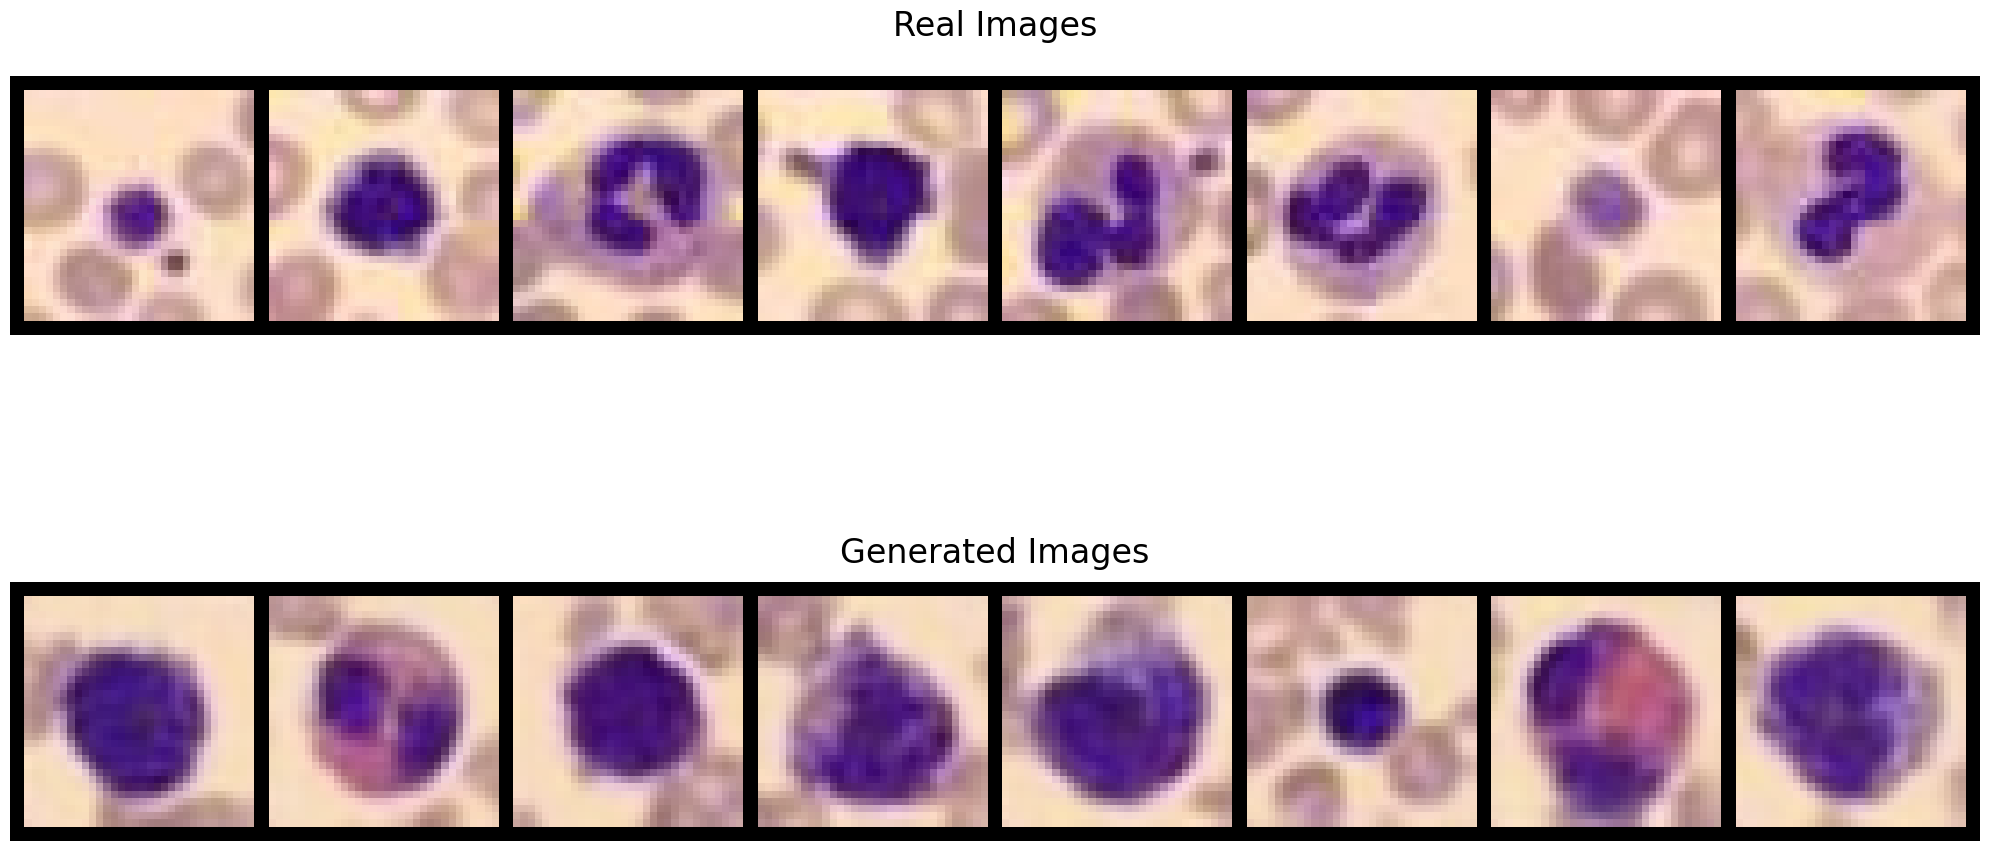

In [20]:
#-------------------- Comparison between real and fake images--------------#

real_batch = next(iter(dataloader))  
real_images = real_batch[0][:8]  

# Generate fake images
fake_sample = cold_diffuse(u_net, fixed_latent_noise, total_steps=timesteps)
fake_images = fake_sample[:8]  

# Create a figure with 2 rows
plt.figure(figsize=(20, 12))  # Slightly taller figure

# Plot real images in first row
plt.subplot(2, 1, 1)
real_grid = vutils.make_grid(real_images.detach().cpu(), nrow=8, normalize=True, padding=2)
plt.imshow(real_grid.numpy().transpose((1, 2, 0)))
plt.axis('off')
plt.title('Real Images', y=1.05, fontsize=24, pad=20)  # Larger font and padding

# Plot fake images in second row
plt.subplot(2, 1, 2)
fake_grid = vutils.make_grid(fake_images.detach().cpu(), nrow=8, normalize=True)
plt.imshow(fake_grid.numpy().transpose((1, 2, 0)))
plt.axis('off')
plt.title('Generated Images', y=1.05, fontsize=24, pad=5)  

plt.tight_layout()  
plt.show()

In [17]:
 # -- SETTINGS --
real_dir = 'real_images'
fake_dir = 'fake_images'
os.makedirs(real_dir, exist_ok=True)
os.makedirs(fake_dir, exist_ok=True)
num_images = 10_000

# Denorm helper (for tensors in [-1,1])
def denorm(x):
    return (x + 1) / 2 if x.min() < 0 else x

# 1) SAVE 10k REAL IMAGES
count = 0
for batch, _ in dataloader:
    for img in batch:
        if count >= num_images:
            break
        save_image(denorm(img).clamp(0,1), 
                   os.path.join(real_dir, f'{count:05d}.png'))
        count += 1
    if count >= num_images:
        break

# 2) GENERATE & SAVE 10k FAKE IMAGES
count = 0
batch_size = fixed_latent_noise.size(0)
while count < num_images:
    fakes = cold_diffuse(u_net, fixed_latent_noise, total_steps=timesteps)
    for img in fakes:
        if count >= num_images:
            break
        save_image(denorm(img).clamp(0,1),
                   os.path.join(fake_dir, f'{count:05d}.png'))
        count += 1

# 3) COMPUTE FID
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
fid_value = calculate_fid_given_paths(
    [real_dir, fake_dir],
    batch_size=50,
    device=device,
    dims=2048
)
print(f'FID score: {fid_value:.4f}')


  0%|          | 0/49 [00:00<?, ?it/s]

  0%|          | 0/49 [00:00<?, ?it/s]

  0%|          | 0/49 [00:00<?, ?it/s]

  0%|          | 0/49 [00:00<?, ?it/s]

  0%|          | 0/49 [00:00<?, ?it/s]

...

  0%|          | 0/49 [00:00<?, ?it/s]

  0%|          | 0/49 [00:00<?, ?it/s]

  0%|          | 0/49 [00:00<?, ?it/s]

Downloading: "https://github.com/mseitzer/pytorch-fid/releases/download/fid_weights/pt_inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/pt_inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:01<00:00, 74.9MB/s]
100%|██████████| 200/200 [00:21<00:00,  9.38it/s]


FID score: 108.4572
